## MTL Trajet: 02 Land Use Purpose Attraction (Flag 2)

### Dataset Overview
MTL Trajet 2016 mobility data with trip purpose, mode, timing, endpoints, trip metrics, and Montréal PUM 2050 destination land-use categories. User IDs distinguish participants, and the point tables provide speed profiles. The single-user case includes a repeated work corridor.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how official destination land-use relates to trip purpose, departure-time concentration, distance, and transport mode across the supplied multiple-user trajectories.

Role: Urban mobility and land-use analyst


Category: Destination land-use, purpose, timing, distance, and transport mode

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do purpose compositions differ between work and Mixte destinations?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

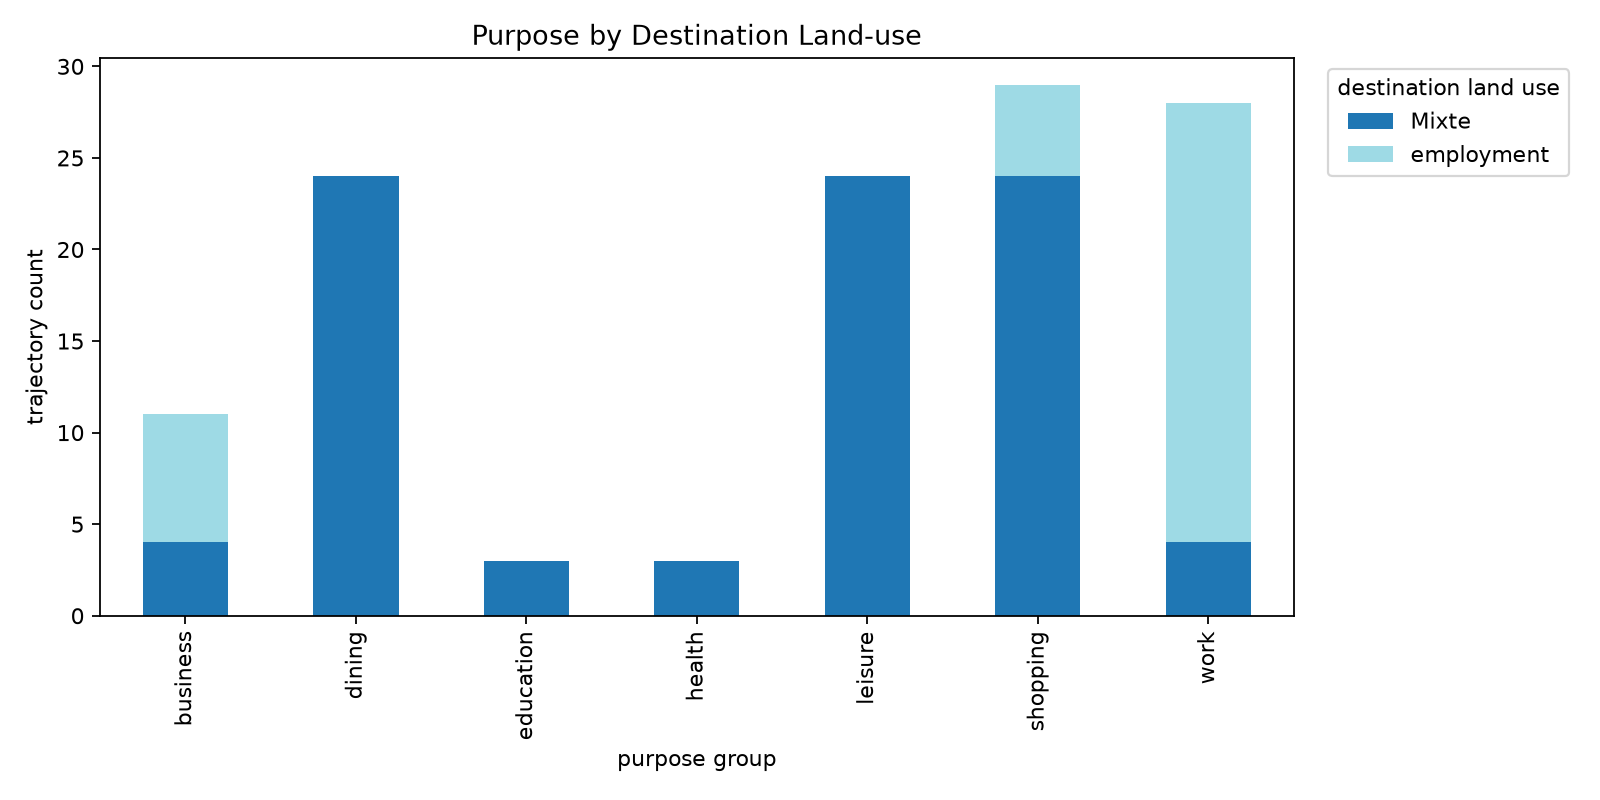

In [ ]:
pd.crosstab(df.destination_land_use, df.purpose_group)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_by_destination_land_use.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "economic_and_mixed_purpose_structure",
  "insight": "Trajectories ending in employment areas more often correspond to work or business purposes, whereas Mixte destinations contain every purpose group represented in this case, including small work and business components alongside shopping, dining, leisure, health, and education.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose Composition by Destination Land-use",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_by_destination_land_use.png"
  },
  "question": "How do purpose compositions differ between work and Mixte destinations?",
  "code": "pd.crosstab(df.destination_land_use, df.purpose_group)",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "trip_purpose",
    "trajectory_id"
  ]
}

### **Question 2**: How does departure-time concentration differ between employment and Mixte destinations?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

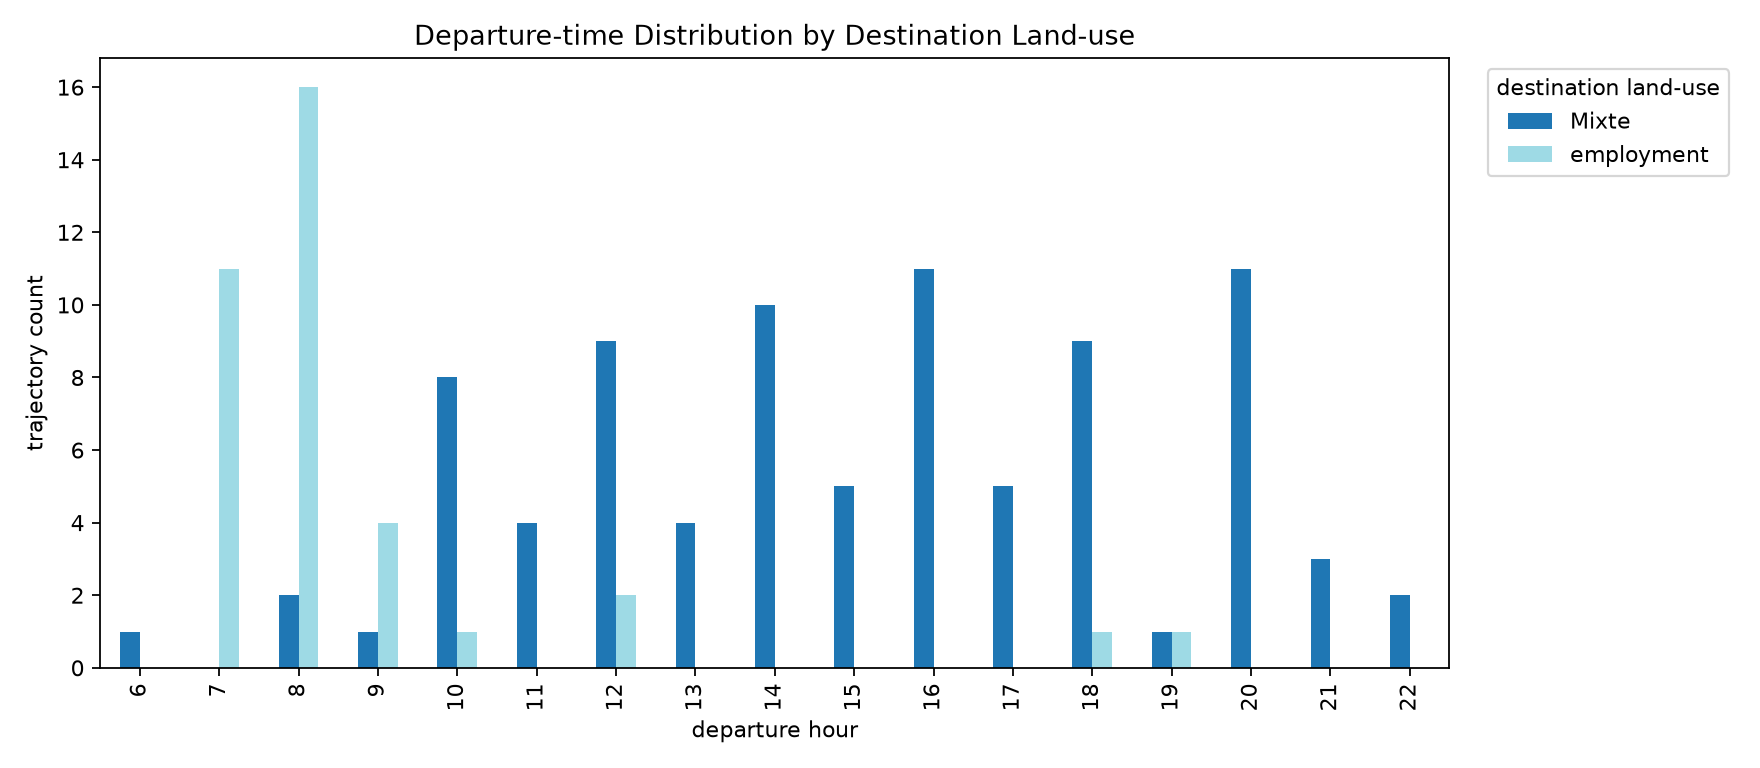

In [ ]:
pd.crosstab(df.destination_land_use, df.start_hour)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/departure_time_by_land_use.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "economic_morning_vs_mixed_time_distribution",
  "insight": "Trips to employment destinations are more concentrated in weekday morning periods, whereas trips to Mixte destinations are distributed more broadly across the day.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Departure Timing by Destination Land-use",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/departure_time_by_land_use.png"
  },
  "question": "How does departure-time concentration differ between employment and Mixte destinations?",
  "code": "pd.crosstab(df.destination_land_use, df.start_hour)",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: How do transport modes vary across distance bands for Mixte versus employment destinations?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

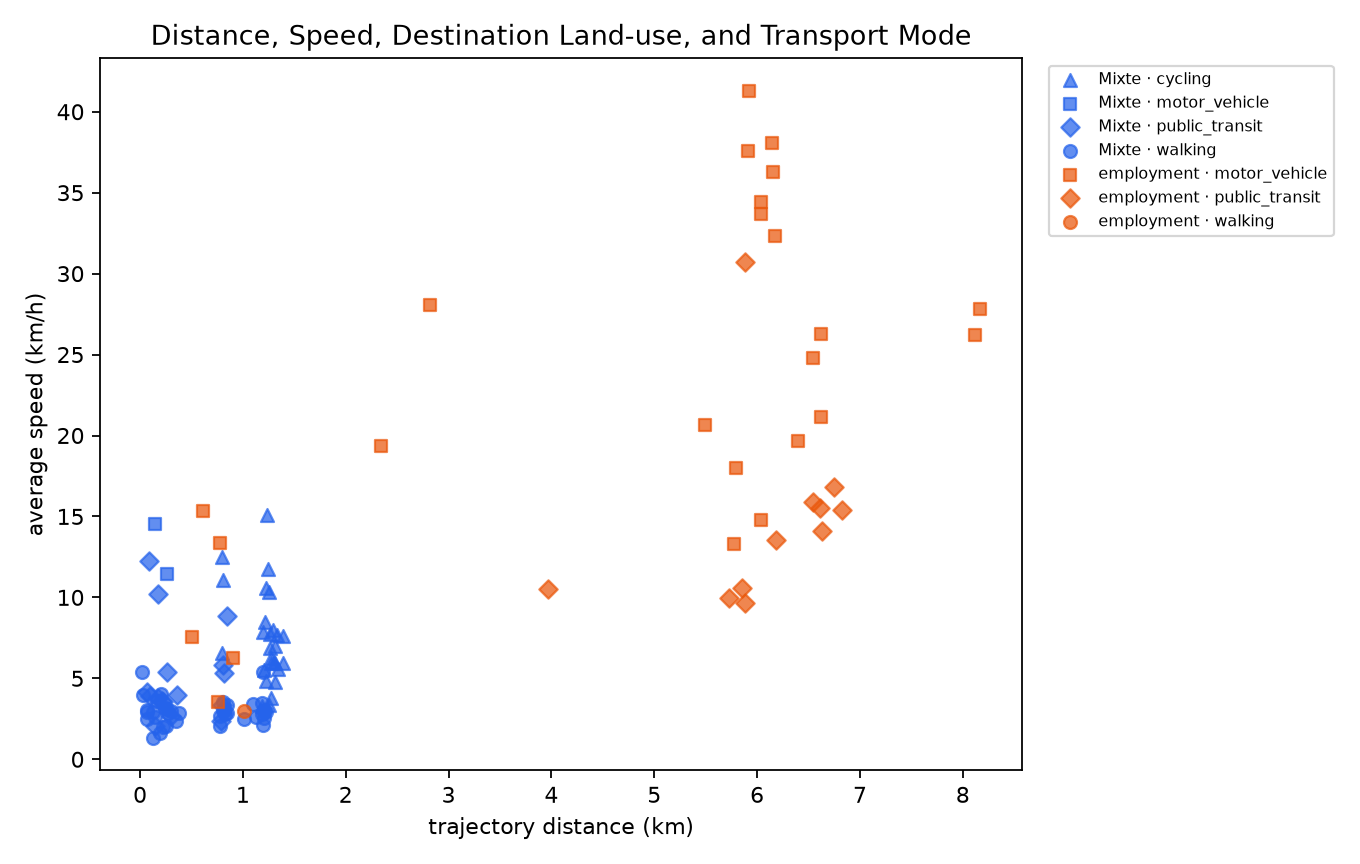

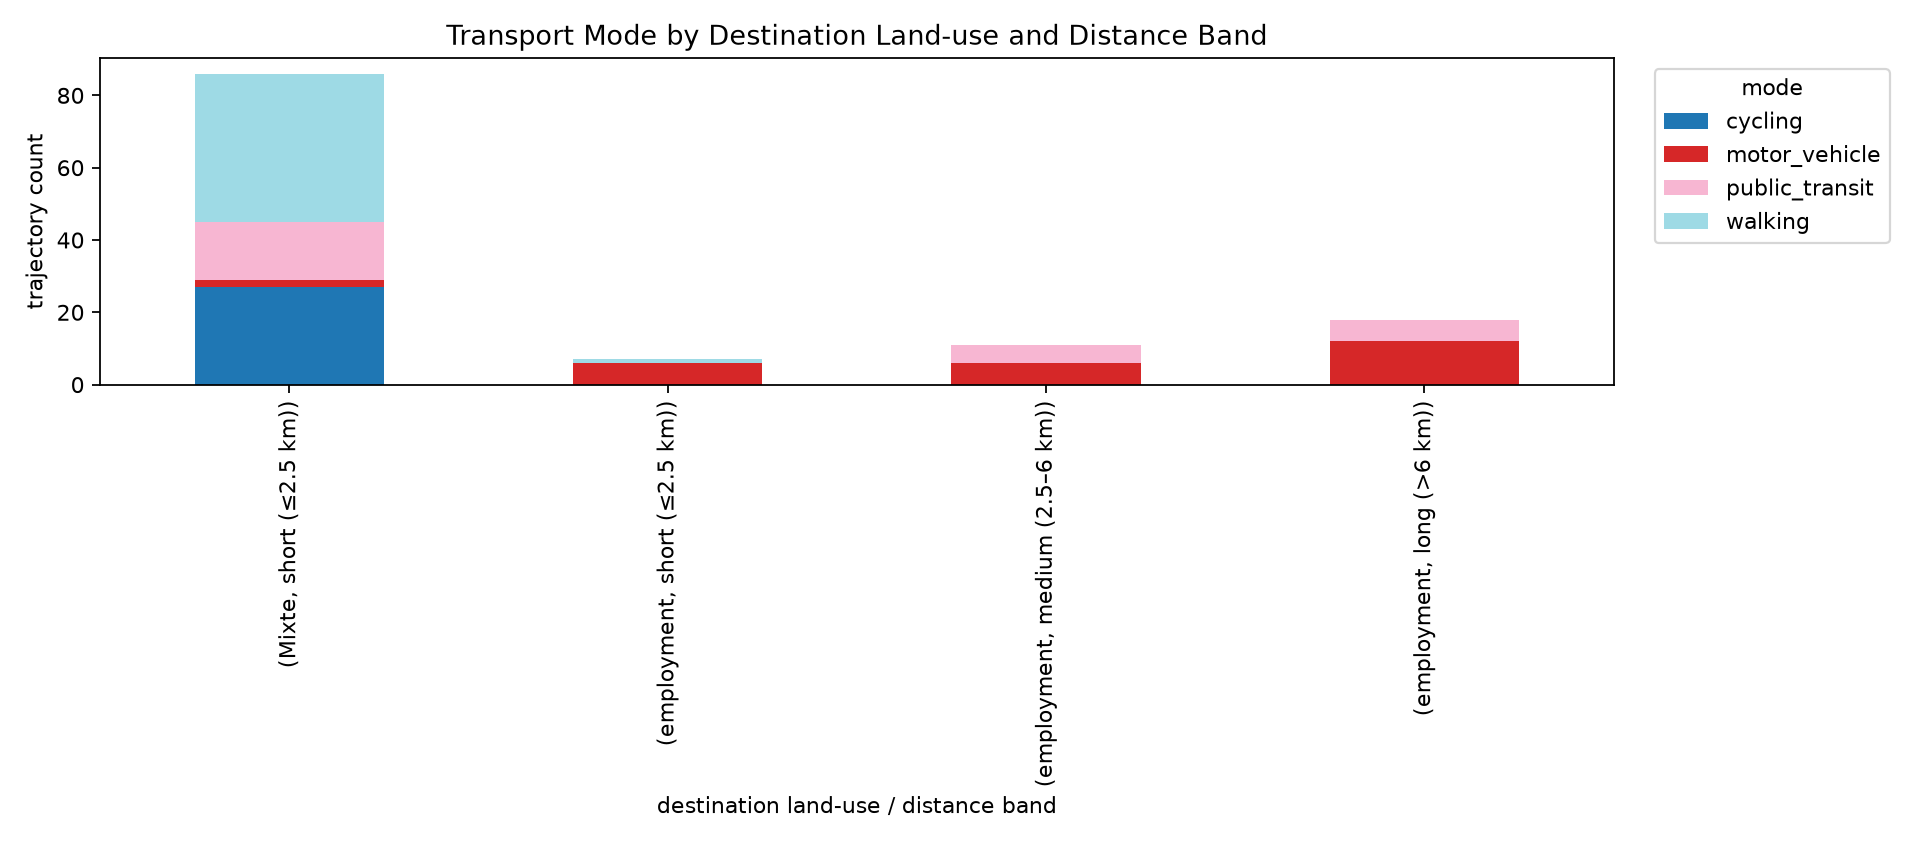

In [ ]:
pd.crosstab([df.destination_land_use, pd.cut(df.distance_km,[0,2.5,6,100])], df.mode_group)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/distance_scatter_by_land_use_mode.png"))
display(Image(filename="visualizations/distance_mode_by_land_use.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "land_use_distance_mode_composition",
  "insight": "Trips to Mixte destinations are typically shorter and more active-mode-oriented, whereas longer trips to employment areas rely more on motorized modes.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Distance and Transport Mode by Land-use",
    "description": "The plot is generated from the supplied case tables.",
    "files": [
      "visualizations/distance_scatter_by_land_use_mode.png",
      "visualizations/distance_mode_by_land_use.png"
    ]
  },
  "question": "How do transport modes vary across distance bands for Mixte versus employment destinations?",
  "code": "pd.crosstab([df.destination_land_use, pd.cut(df.distance_km,[0,2.5,6,100])], df.mode_group)",
  "insight_type": "factor_relationship",
  "evidence": "Trajectories to Mixte destinations are generally short in this case. Transport-mode composition also changes substantially with trajectory distance and destination land-use: short trajectories to Mixte destinations more often use walking or cycling, while longer trajectories to employment destinations rely more on motor vehicles or public transit.",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "transport_mode",
    "trajectory_id",
    "point_speed"
  ]
}

### Summary of Findings (Flag 2)

Employment destinations are more often associated with work or business purposes and with morning travel. Mixte destinations include every purpose group represented in this case, span a broader range of departure times, and more often receive short walking or cycling trips; longer trips to employment destinations rely more on motor vehicles or public transit.